# Assignment 03: Toxic Comment Classification on Civil Comments
**Transfer learning, fine-tuning, hyperparameter tuning and interpretability with DistilBERT**

Name: Khandakar Humyra Oyshi


Student ID: 1000128211

Run on Google Colab with a GPU: *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.
Expected total run time on a T4 is roughly 60–80 minutes (most of it is the Optuna search).

Pipeline:
1. **Load and subsample**: Civil Comments, binarise toxicity at 0.5
2. **Frozen baseline**: DistilBERT as a frozen feature extractor + logistic regression
3. **Fine-tuning**: unfreeze and train DistilBERT end-to-end (default hyperparameters)
4. **Hyperparameter tuning**: Optuna TPE search over 5 hyperparameters, then retrain with the best ones
5. **Real-world test** on hand-written comments
6. **Interpretability** with SHAP on a small, selected set of predictions

## 0. Setup

In [1]:
!pip install -q transformers datasets accelerate optuna shap scikit-learn tabulate

In [2]:
import os, gc, math, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from tqdm.auto import tqdm
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)
import optuna
import shap

warnings.filterwarnings("ignore")

# ---------------- configuration ----------------
SEED = 42
MODEL_NAME = "distilbert-base-uncased"
THRESHOLD = 0.5            # toxicity >= 0.5  -> toxic (1)
N_TRAIN, N_VAL, N_TEST = 20_000, 4_000, 4_000
N_TUNE_TRAIN = 8_000       # smaller train set used inside each Optuna trial (time budget)
N_TRIALS = 12
MAX_LEN = 128
OUT_DIR, IMG_DIR = "outputs", "images"
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(IMG_DIR, exist_ok=True)

ID2LABEL = {0: "non_toxic", 1: "toxic"}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}

set_seed(SEED); random.seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

Device: cuda Tesla T4


## 1. Data
Civil Comments has ~1.8M training comments. To fit a free Colab budget we take a **random subset**
of each official split. A comment is labelled **toxic if `toxicity >= 0.5`** (the threshold used by the
dataset authors, meaning at least half of the annotators rated it toxic).

In [3]:
raw = load_dataset("google/civil_comments")
print(raw)

def make_subset(split, n):
    d = raw[split].shuffle(seed=SEED).select(range(n))
    d = d.filter(lambda x: x["text"] is not None and len(x["text"].strip()) > 0)
    d = d.map(lambda x: {"label": int(x["toxicity"] >= THRESHOLD)})
    return d.select_columns(["text", "toxicity", "label"])

train_ds = make_subset("train", N_TRAIN)
val_ds   = make_subset("validation", N_VAL)
test_ds  = make_subset("test", N_TEST)

balance = pd.DataFrame({name: pd.Series(list(d["label"])).value_counts().sort_index()
                        for name, d in [("train", train_ds), ("val", val_ds), ("test", test_ds)]})
balance.index = [ID2LABEL[i] for i in balance.index]
balance.loc["% toxic"] = (balance.loc["toxic"] / balance.sum() * 100).round(2)
balance

README.md:   0%|          | 0.00/7.73k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

... (10 outputs left out)

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

,train,val,test
non_toxic,18387.00,3662.00,3684.0
toxic,1613.00,338.00,316.0
% toxic,8.06,8.45,7.9


The data is **heavily imbalanced** (only a small share of comments are toxic), so accuracy alone is
misleading: a model that always says "non-toxic" would score above 90%. We therefore report
**precision, recall and F1 for the toxic class**, macro-F1, ROC-AUC and PR-AUC, and use **toxic-class F1**
as the main metric for model selection.

In [4]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def tok_fn(batch):
    return tok(batch["text"], truncation=True, max_length=MAX_LEN)

train_tok = train_ds.map(tok_fn, batched=True, remove_columns=["text", "toxicity"])
val_tok   = val_ds.map(tok_fn, batched=True, remove_columns=["text", "toxicity"])
test_tok  = test_ds.map(tok_fn, batched=True, remove_columns=["text", "toxicity"])
collator  = DataCollatorWithPadding(tok)

def metrics_from_probs(y_true, probs, thr=0.5):
    y_true = np.asarray(y_true); y_pred = (np.asarray(probs) >= thr).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": p, "recall": r, "f1": f,
            "macro_f1": f1_score(y_true, y_pred, average="macro"),
            "roc_auc": roc_auc_score(y_true, probs), "pr_auc": average_precision_score(y_true, probs)}

def softmax_np(logits):
    return torch.softmax(torch.tensor(logits, dtype=torch.float32), -1).numpy()

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return metrics_from_probs(labels, softmax_np(logits)[:, 1])

results = {}   # test-set metrics for every model, filled in below

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

## 2. Transfer learning: frozen baseline
DistilBERT is loaded with **all weights frozen** and used only to turn each comment into a 768-dim
vector (mean of the last hidden states over real tokens). A logistic regression is trained on those
vectors. `class_weight="balanced"` compensates for the class imbalance.

In [5]:
encoder = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
for p in encoder.parameters():
    p.requires_grad = False
print("Trainable encoder params:", sum(p.numel() for p in encoder.parameters() if p.requires_grad))

@torch.no_grad()
def embed(texts, bs=128):
    out = []
    for i in tqdm(range(0, len(texts), bs)):
        enc = tok(texts[i:i+bs], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(device)
        with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
            h = encoder(**enc).last_hidden_state
        m = enc["attention_mask"].unsqueeze(-1).float()
        out.append(((h.float() * m).sum(1) / m.sum(1)).cpu().numpy())
    return np.vstack(out)

X_train, X_val, X_test = embed(list(train_ds["text"])), embed(list(val_ds["text"])), embed(list(test_ds["text"]))
y_train, y_val, y_test = np.array(train_ds["label"]), np.array(val_ds["label"]), np.array(test_ds["label"])

baseline = make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED))
baseline.fit(X_train, y_train)

base_val  = metrics_from_probs(y_val,  baseline.predict_proba(X_val)[:, 1])
base_test = metrics_from_probs(y_test, baseline.predict_proba(X_test)[:, 1])
results["1. Frozen DistilBERT + LogReg (baseline)"] = base_test
pd.DataFrame({"val": base_val, "test": base_test}).round(4)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable encoder params: 0


  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]

,val,test
accuracy,0.8120,0.8070
precision,0.2642,0.2427
recall,0.6864,0.6804
f1,0.3816,0.3577
macro_f1,0.6354,0.6221
roc_auc,0.8433,0.8479
pr_auc,0.4176,0.4270


In [6]:
del encoder; gc.collect(); torch.cuda.empty_cache()

## 3. Fine-tuning end-to-end (default hyperparameters)
All DistilBERT weights are now trainable, with a 2-class classification head on top.
To handle the imbalance we use a **class-weighted cross-entropy** (toxic weight = sqrt(neg/pos)).
Hyperparameters are common defaults for BERT fine-tuning: lr 2e-5, batch 32, 2 epochs,
weight decay 0.01, 10% warmup.

In [7]:
neg, pos = np.bincount(y_train)
CLASS_WEIGHTS = torch.tensor([1.0, math.sqrt(neg / pos)], dtype=torch.float)
print("Class weights:", CLASS_WEIGHTS)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = nn.functional.cross_entropy(outputs.logits, labels,
                                           weight=CLASS_WEIGHTS.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

def make_model():
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID)

def make_args(run_name, lr, bs, epochs, wd, warmup_ratio, n_train):
    total_steps = math.ceil(n_train / bs) * epochs
    return TrainingArguments(
        output_dir=f"{OUT_DIR}/runs/{run_name}",
        learning_rate=lr, per_device_train_batch_size=bs, per_device_eval_batch_size=64,
        num_train_epochs=epochs, weight_decay=wd, warmup_steps=int(warmup_ratio * total_steps),
        eval_strategy="epoch", save_strategy="no", logging_steps=50,
        fp16=torch.cuda.is_available(), report_to="none", seed=SEED)

def build_trainer(run_name, train_set, lr, bs, epochs, wd, warmup_ratio):
    return WeightedTrainer(model=make_model(),
                           args=make_args(run_name, lr, bs, epochs, wd, warmup_ratio, len(train_set)),
                           train_dataset=train_set, eval_dataset=val_tok,
                           data_collator=collator, compute_metrics=compute_metrics)

def test_eval(trainer):
    pred = trainer.predict(test_tok)
    probs = softmax_np(pred.predictions)[:, 1]
    return metrics_from_probs(pred.label_ids, probs), probs

Class weights: tensor([1.0000, 3.3763])


In [8]:
DEFAULT_HP = dict(lr=2e-5, bs=32, epochs=2, wd=0.01, warmup_ratio=0.1)
ft_trainer = build_trainer("finetune_default", train_tok, **DEFAULT_HP)
ft_trainer.train()

ft_val = ft_trainer.evaluate()
ft_test, ft_test_probs = test_eval(ft_trainer)
results["2. Fine-tuned DistilBERT (default HP)"] = ft_test
pd.DataFrame({"val": {k.replace("eval_", ""): v for k, v in ft_val.items() if k.replace("eval_", "") in ft_test},
              "test": ft_test}).round(4)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1,Roc Auc,Pr Auc
1,0.261550,0.262747,0.935500,0.603093,0.692308,0.644628,0.804580,0.940454,0.710882
2,0.227559,0.289863,0.939500,0.633333,0.674556,0.653295,0.810077,0.940862,0.723741


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Macro F1,Roc Auc,Pr Auc
0.227559,0.289863,2,0.939500,0.633333,0.674556,0.653295,0.810077,0.940862,0.723741


,val,test
accuracy,0.9395,0.9400
precision,0.6333,0.6105
recall,0.6746,0.6646
f1,0.6533,0.6364
macro_f1,0.8101,0.8018
roc_auc,0.9409,0.9289
pr_auc,0.7237,0.6911


In [9]:
del ft_trainer; gc.collect(); torch.cuda.empty_cache()

## 4. Hyperparameter tuning with Optuna (TPE)
**Search method:** Optuna's Tree-structured Parzen Estimator (Bayesian optimisation). It uses the results
of earlier trials to propose promising settings, so it needs far fewer trials than grid search.

**Search space (5 hyperparameters):**

| Hyperparameter | Range |
|---|---|
| learning rate | 1e-5 – 6e-5 (log scale) |
| batch size | {16, 32} |
| epochs | 1 – 3 |
| weight decay | 0.0 – 0.1 |
| warmup ratio | 0.0 – 0.2 |

**Objective:** toxic-class F1 on the validation set. To keep each trial affordable, trials train on an
8,000-comment slice of the training subset; the best configuration is then retrained on the full
20,000-comment subset and evaluated once on the test set.

In [10]:
tune_train = train_tok.select(range(N_TUNE_TRAIN))

def objective(trial):
    hp = dict(lr=trial.suggest_float("learning_rate", 1e-5, 6e-5, log=True),
              bs=trial.suggest_categorical("batch_size", [16, 32]),
              epochs=trial.suggest_int("epochs", 1, 3),
              wd=trial.suggest_float("weight_decay", 0.0, 0.1),
              warmup_ratio=trial.suggest_float("warmup_ratio", 0.0, 0.2))
    trainer = build_trainer(f"trial_{trial.number}", tune_train, **hp)
    trainer.train()
    m = trainer.evaluate()
    for k in ["precision", "recall", "roc_auc", "pr_auc"]:
        trial.set_user_attr(k, round(m[f"eval_{k}"], 4))
    del trainer; gc.collect(); torch.cuda.empty_cache()
    return m["eval_f1"]

optuna.logging.set_verbosity(optuna.logging.INFO)
study = optuna.create_study(direction="maximize", study_name="distilbert_toxicity",
                            sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS)
print("Best val F1:", round(study.best_value, 4)); print("Best params:", study.best_params)

[I 2026-11-07 11:15:24,456] A new study created in memory with name: distilbert_toxicity


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1,Roc Auc,Pr Auc
1,0.354132,0.377958,0.944750,0.788177,0.473373,0.591497,0.780934,0.927323,0.689242
2,0.216029,0.413962,0.943250,0.692042,0.591716,0.637959,0.803585,0.924983,0.690410


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Macro F1,Roc Auc,Pr Auc
0.216029,0.413962,2,0.943250,0.692042,0.591716,0.637959,0.803585,0.924983,0.690410


[I 2026-11-07 11:16:38,659] Trial 0 finished with value: 0.6379585326953748 and parameters: {'learning_rate': 1.9563603928236998e-05, 'batch_size': 16, 'epochs': 2, 'weight_decay': 0.015601864044243652, 'warmup_ratio': 0.031198904067240532}. Best is trial 0 with value: 0.6379585326953748.


... (52 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1,Roc Auc,Pr Auc
1,0.339971,0.299420,0.932750,0.595041,0.639053,0.616262,0.789704,0.935394,0.683450


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Macro F1,Roc Auc,Pr Auc
0.339971,0.299420,1,0.932750,0.595041,0.639053,0.616262,0.789704,0.935394,0.683450


[I 2026-11-07 11:29:52,916] Trial 11 finished with value: 0.6162624821683309 and parameters: {'learning_rate': 4.937565170462481e-05, 'batch_size': 16, 'epochs': 1, 'weight_decay': 0.04603724332554639, 'warmup_ratio': 0.08287344492247603}. Best is trial 0 with value: 0.6379585326953748.


Best val F1: 0.638
Best params: {'learning_rate': 1.9563603928236998e-05, 'batch_size': 16, 'epochs': 2, 'weight_decay': 0.015601864044243652, 'warmup_ratio': 0.031198904067240532}


### Tuning results

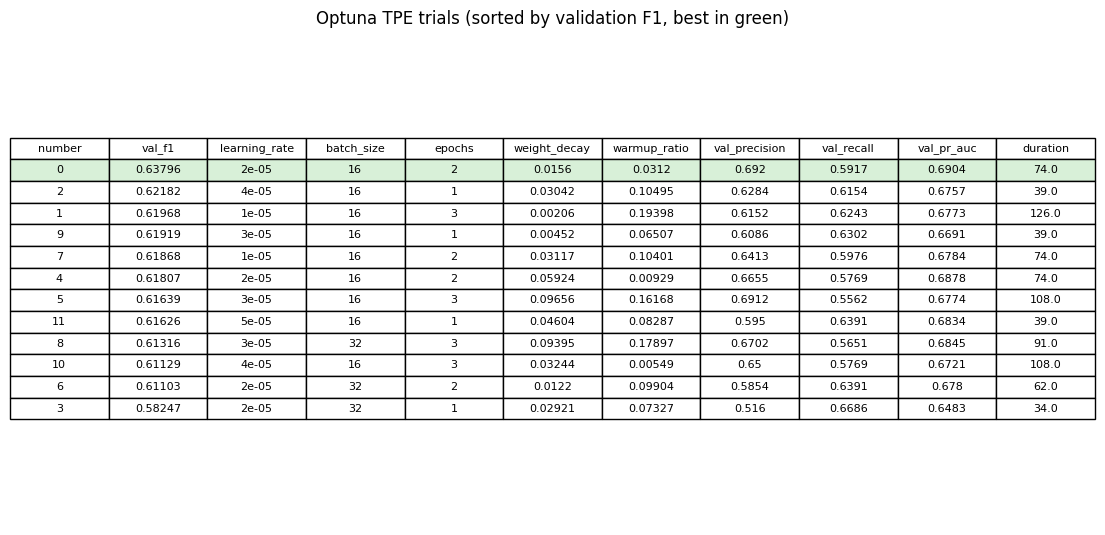

,number,val_f1,learning_rate,batch_size,epochs,weight_decay,warmup_ratio,val_precision,val_recall,val_pr_auc,duration
0,0,0.63796,0.00002,16,2,0.01560,0.03120,0.6920,0.5917,0.6904,74.0
2,2,0.62182,0.00004,16,1,0.03042,0.10495,0.6284,0.6154,0.6757,39.0
1,1,0.61968,0.00001,16,3,0.00206,0.19398,0.6152,0.6243,0.6773,126.0
9,9,0.61919,0.00003,16,1,0.00452,0.06507,0.6086,0.6302,0.6691,39.0
7,7,0.61868,0.00001,16,2,0.03117,0.10401,0.6413,0.5976,0.6784,74.0
4,4,0.61807,0.00002,16,2,0.05924,0.00929,0.6655,0.5769,0.6878,74.0
5,5,0.61639,0.00003,16,3,0.09656,0.16168,0.6912,0.5562,0.6774,108.0
11,11,0.61626,0.00005,16,1,0.04604,0.08287,0.5950,0.6391,0.6834,39.0
8,8,0.61316,0.00003,32,3,0.09395,0.17897,0.6702,0.5651,0.6845,91.0
10,10,0.61129,0.00004,16,3,0.03244,0.00549,0.6500,0.5769,0.6721,108.0


In [11]:
trials_df = study.trials_dataframe()
trials_df = trials_df.rename(columns=lambda c: c.replace("params_", "").replace("user_attrs_", "val_"))
keep = ["number", "value", "learning_rate", "batch_size", "epochs", "weight_decay", "warmup_ratio",
        "val_precision", "val_recall", "val_pr_auc", "duration"]
trials_df = trials_df[[c for c in keep if c in trials_df]].rename(columns={"value": "val_f1"})
trials_df["duration"] = trials_df["duration"].dt.total_seconds().round(0)
trials_df = trials_df.sort_values("val_f1", ascending=False).round(5)
trials_df.to_csv(f"{OUT_DIR}/optuna_trials.csv", index=False)

# table as an image, ready to put in the README
fig, ax = plt.subplots(figsize=(14, 0.45 * len(trials_df) + 1)); ax.axis("off")
tbl = ax.table(cellText=trials_df.astype(str).values, colLabels=trials_df.columns, loc="center", cellLoc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(8); tbl.scale(1, 1.3)
for j in range(len(trials_df.columns)):
    tbl[(1, j)].set_facecolor("#d8f0d8")    # highlight best trial
ax.set_title("Optuna TPE trials (sorted by validation F1, best in green)")
plt.savefig(f"{IMG_DIR}/tuning_table.png", dpi=200, bbox_inches="tight"); plt.show()
trials_df

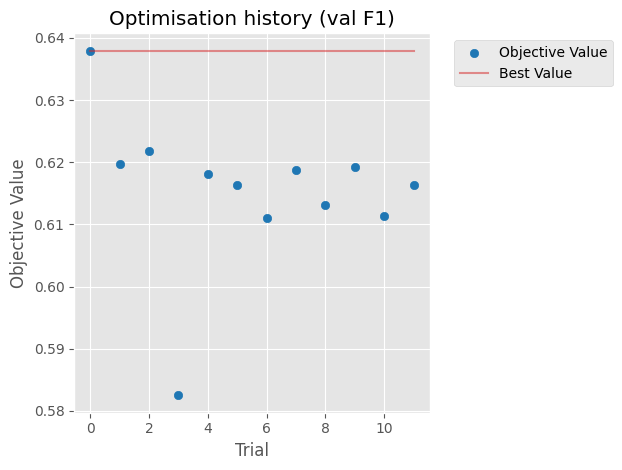

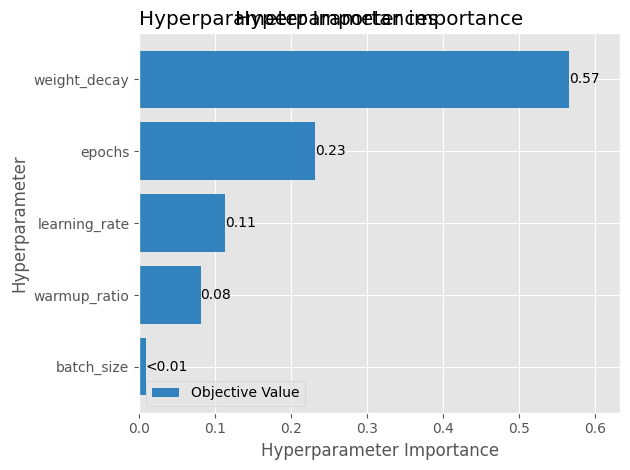

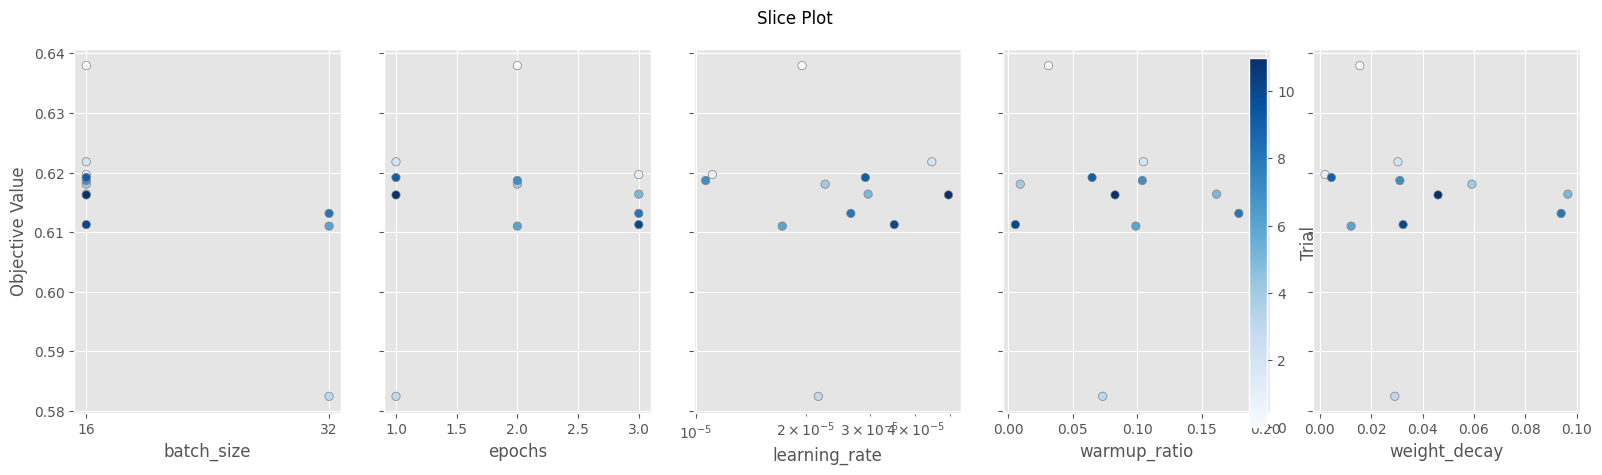

In [12]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances, plot_slice

plot_optimization_history(study); plt.title("Optimisation history (val F1)")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/optuna_history.png", dpi=200); plt.show()

plot_param_importances(study); plt.title("Hyperparameter importance")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/optuna_importance.png", dpi=200); plt.show()

plot_slice(study); plt.tight_layout(); plt.savefig(f"{IMG_DIR}/optuna_slice.png", dpi=200); plt.show()

### Retrain with the best hyperparameters on the full training subset

In [13]:
bp = study.best_params
BEST_HP = dict(lr=bp["learning_rate"], bs=bp["batch_size"], epochs=bp["epochs"],
               wd=bp["weight_decay"], warmup_ratio=bp["warmup_ratio"])
print(BEST_HP)

best_trainer = build_trainer("finetune_tuned", train_tok, **BEST_HP)
best_trainer.train()
tuned_test, tuned_test_probs = test_eval(best_trainer)
results["3. Fine-tuned DistilBERT (Optuna-tuned HP)"] = tuned_test

model = best_trainer.model.eval()
model.save_pretrained(f"{OUT_DIR}/best_model"); tok.save_pretrained(f"{OUT_DIR}/best_model")  # not committed
pd.Series(tuned_test).round(4)

{'lr': 1.9563603928236998e-05, 'bs': 16, 'epochs': 2, 'wd': 0.015601864044243652, 'warmup_ratio': 0.031198904067240532}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1,Roc Auc,Pr Auc
1,0.464417,0.336807,0.942750,0.744395,0.491124,0.591800,0.780508,0.937961,0.697501
2,0.307124,0.377408,0.940500,0.653374,0.630178,0.641566,0.804562,0.940117,0.715160


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,0
accuracy,0.9422
precision,0.6332
recall,0.6392
f1,0.6362
macro_f1,0.8024
roc_auc,0.9326
pr_auc,0.6721


## 5. Comparison: frozen baseline vs fine-tuned vs tuned

|                                            |   accuracy |   precision |   recall |     f1 |   macro_f1 |   roc_auc |   pr_auc |
|:-------------------------------------------|-----------:|------------:|---------:|-------:|-----------:|----------:|---------:|
| 1. Frozen DistilBERT + LogReg (baseline)   |     0.807  |      0.2427 |   0.6804 | 0.3577 |     0.6221 |    0.8479 |   0.427  |
| 2. Fine-tuned DistilBERT (default HP)      |     0.94   |      0.6105 |   0.6646 | 0.6364 |     0.8018 |    0.9289 |   0.6911 |
| 3. Fine-tuned DistilBERT (Optuna-tuned HP) |     0.9422 |      0.6332 |   0.6392 | 0.6362 |     0.8024 |    0.9326 |   0.6721 |


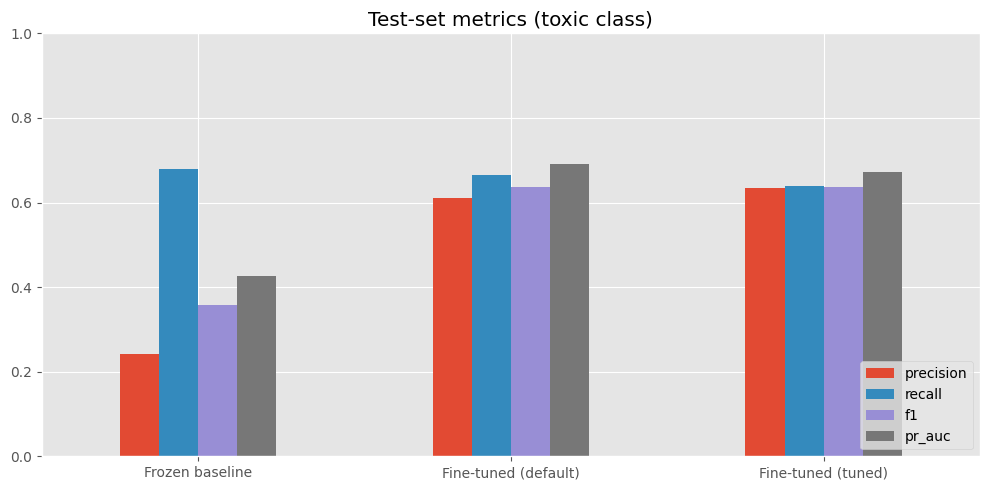

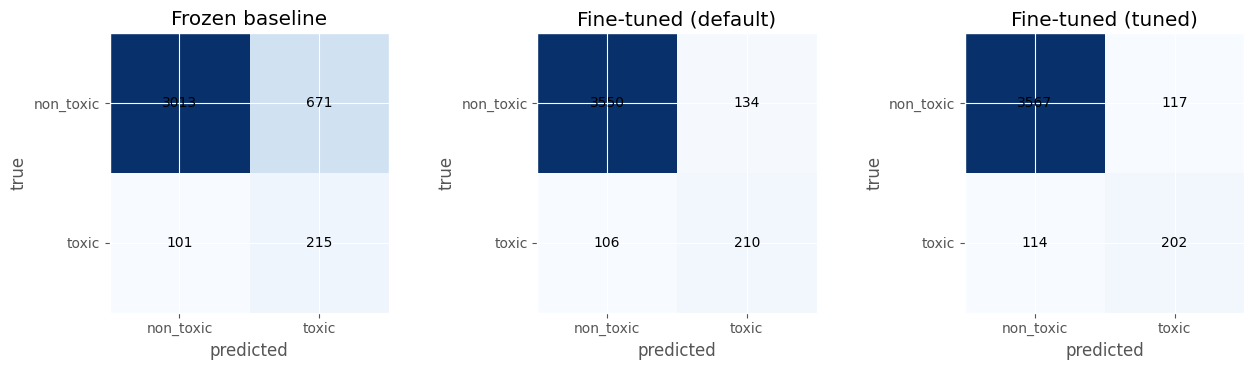

In [14]:
res_df = pd.DataFrame(results).T.round(4)
res_df.to_csv(f"{OUT_DIR}/results.csv")
print(res_df.to_markdown())   # paste this table into the README

ax = res_df[["precision", "recall", "f1", "pr_auc"]].plot.bar(figsize=(10, 5), rot=0)
ax.set_xticklabels(["Frozen baseline", "Fine-tuned (default)", "Fine-tuned (tuned)"])
ax.set_ylim(0, 1); ax.set_title("Test-set metrics (toxic class)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/model_comparison.png", dpi=200); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
base_probs = baseline.predict_proba(X_test)[:, 1]
for ax, (name, probs) in zip(axes, [("Frozen baseline", base_probs), ("Fine-tuned (default)", ft_test_probs),
                                    ("Fine-tuned (tuned)", tuned_test_probs)]):
    cm = confusion_matrix(y_test, (probs >= 0.5).astype(int))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", color="black")
    ax.set_xticks([0, 1], ["non_toxic", "toxic"]); ax.set_yticks([0, 1], ["non_toxic", "toxic"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(name)
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/confusion_matrices.png", dpi=200); plt.show()

## 6. Real-world test


In [15]:
@torch.no_grad()
def predict_proba(texts, bs=32):
    model.eval(); out = []
    for i in range(0, len(texts), bs):
        enc = tok(list(texts[i:i+bs]), truncation=True, max_length=MAX_LEN, padding=True,
                  return_tensors="pt").to(model.device)
        out.append(torch.softmax(model(**enc).logits.float(), -1).cpu().numpy())
    return np.vstack(out)   # shape (n, 2): [p(non_toxic), p(toxic)]

real_world = [
    ("Thanks for sharing this, the article was really well researched.", "non_toxic"),
    ("I completely disagree with the mayor's new parking policy, it will hurt small shops.", "non_toxic"),
    ("You are a complete idiot and nobody wants to hear your stupid opinions.", "toxic"),
    ("Shut up, loser. Go back to whatever hole you crawled out of.", "toxic"),
    ("As a gay man, I think this law will finally protect families like mine.", "non_toxic"),
    ("This movie was so bad it killed me, I laughed the whole time.", "non_toxic"),
    ("Oh great, another genius who thinks reading one headline makes him an expert.", "toxic"),
    ("People like you are the reason this country is going down the drain, pathetic.", "toxic"),
]
texts = [t for t, _ in real_world]
p_tox = predict_proba(texts)[:, 1]
rw_df = pd.DataFrame({"input": texts, "p_toxic": p_tox.round(3),
                      "predicted": np.where(p_tox >= 0.5, "toxic", "non_toxic"),
                      "expected": [e for _, e in real_world]})
rw_df["check"] = np.where(rw_df.predicted == rw_df.expected, "correct", "WRONG")
rw_df.to_csv(f"{OUT_DIR}/real_world_test.csv", index=False)
print(rw_df.to_markdown(index=False))
rw_df

| input                                                                                |   p_toxic | predicted   | expected   | check   |
|:-------------------------------------------------------------------------------------|----------:|:------------|:-----------|:--------|
| Thanks for sharing this, the article was really well researched.                     |     0.002 | non_toxic   | non_toxic  | correct |
| I completely disagree with the mayor's new parking policy, it will hurt small shops. |     0.002 | non_toxic   | non_toxic  | correct |
| You are a complete idiot and nobody wants to hear your stupid opinions.              |     0.994 | toxic       | toxic      | correct |
| Shut up, loser. Go back to whatever hole you crawled out of.                         |     0.993 | toxic       | toxic      | correct |
| As a gay man, I think this law will finally protect families like mine.              |     0.952 | toxic       | non_toxic  | WRONG   |
| This movie was so bad it killed 

,input,p_toxic,predicted,expected,check
0,"Thanks for sharing this, the article was reall...",0.002,non_toxic,non_toxic,correct
1,I completely disagree with the mayor's new par...,0.002,non_toxic,non_toxic,correct
2,You are a complete idiot and nobody wants to h...,0.994,toxic,toxic,correct
3,"Shut up, loser. Go back to whatever hole you c...",0.993,toxic,toxic,correct
4,"As a gay man, I think this law will finally pr...",0.952,toxic,non_toxic,WRONG
5,"This movie was so bad it killed me, I laughed ...",0.006,non_toxic,non_toxic,correct
6,"Oh great, another genius who thinks reading on...",0.003,non_toxic,toxic,WRONG
7,People like you are the reason this country is...,0.994,toxic,toxic,correct


## 7. Interpretability with SHAP
SHAP (Partition explainer with a text masker) hides groups of tokens and measures how the toxic
probability changes, giving each token a contribution: **red pushes towards toxic, blue towards
non-toxic**. We explain a small, deliberately chosen set: 2 true positives, 1 true negative,
1 false positive, 1 false negative from the test set, plus 2 real-world comments.

In [16]:
test_df = pd.DataFrame({"text": list(test_ds["text"]), "label": y_test, "p_toxic": tuned_test_probs})
test_df["pred"] = (test_df.p_toxic >= 0.5).astype(int)
short = test_df[test_df.text.str.len().between(30, 250)]

def pick(mask, n, tag):
    s = short[mask]
    return s.sample(min(n, len(s)), random_state=SEED).assign(case=tag)

sel = pd.concat([pick((short.label == 1) & (short.pred == 1), 2, "true positive"),
                 pick((short.label == 0) & (short.pred == 0), 1, "true negative"),
                 pick((short.label == 0) & (short.pred == 1), 1, "false positive"),
                 pick((short.label == 1) & (short.pred == 0), 1, "false negative")])
rw_pick = rw_df.iloc[[2, 4]]
sel = pd.concat([sel, pd.DataFrame({"text": rw_pick.input, "label": rw_pick.expected.map(LABEL2ID),
                                    "p_toxic": rw_pick.p_toxic, "pred": rw_pick.predicted.map(LABEL2ID),
                                    "case": "real-world"})]).reset_index(drop=True)
sel[["case", "label", "pred", "p_toxic", "text"]]

,case,label,pred,p_toxic,text
0,true positive,1,1,0.987923,That's such a ridiculous comment ...... If you...
1,true positive,1,1,0.991620,Stupid to hold these meetings in the heart of ...
2,true negative,0,0,0.006758,Got your till foil hat on again lefty !
3,false positive,0,1,0.759181,Well aint you just a consistant persisitant sh...
4,false negative,1,0,0.010798,The Palestinians should thank this guy for kee...
5,real-world,1,1,0.994000,You are a complete idiot and nobody wants to h...
6,real-world,0,1,0.952000,"As a gay man, I think this law will finally pr..."


In [17]:
masker = shap.maskers.Text(tok)
explainer = shap.Explainer(lambda x: predict_proba(list(x)), masker, output_names=["non_toxic", "toxic"])
shap_values = explainer(sel.text.tolist())

shap.plots.text(shap_values[:, :, 1])     # interactive view, screenshot for README
with open(f"{IMG_DIR}/shap_text.html", "w") as f:
    f.write(shap.plots.text(shap_values[:, :, 1], display=False))

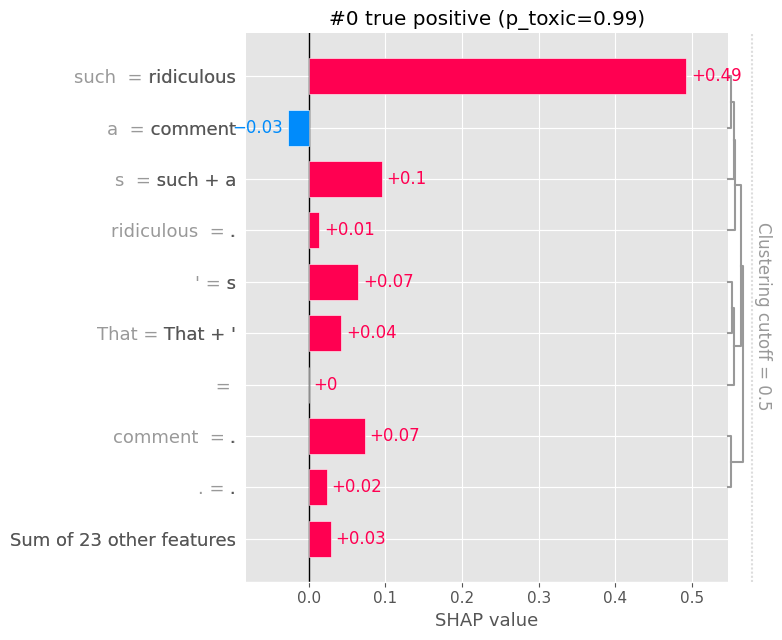

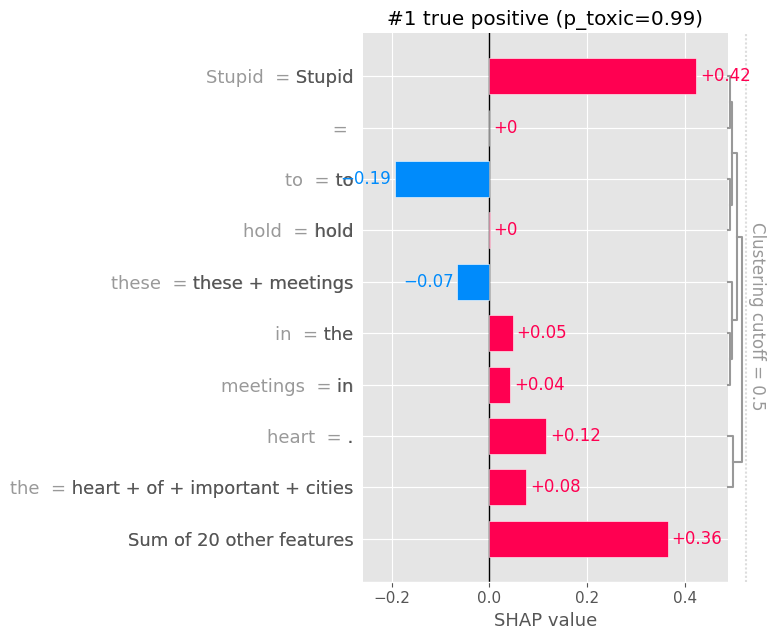

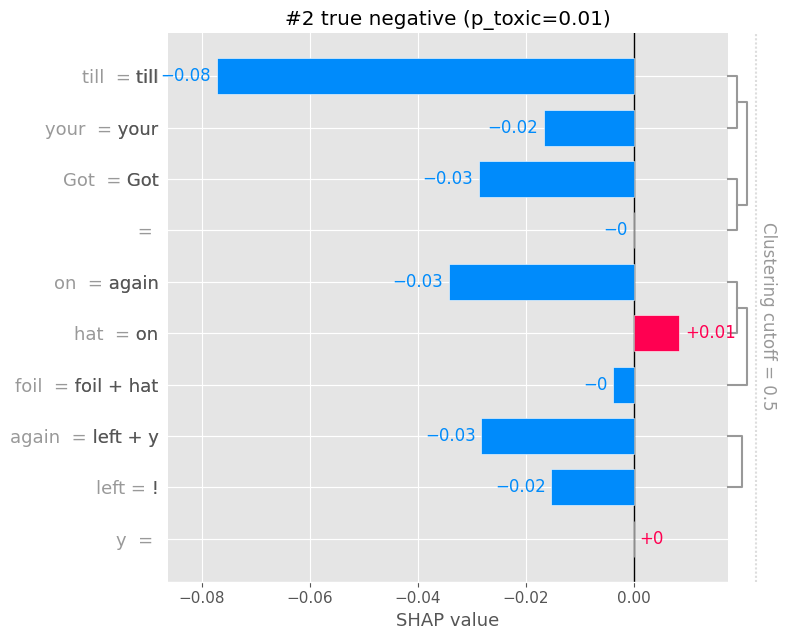

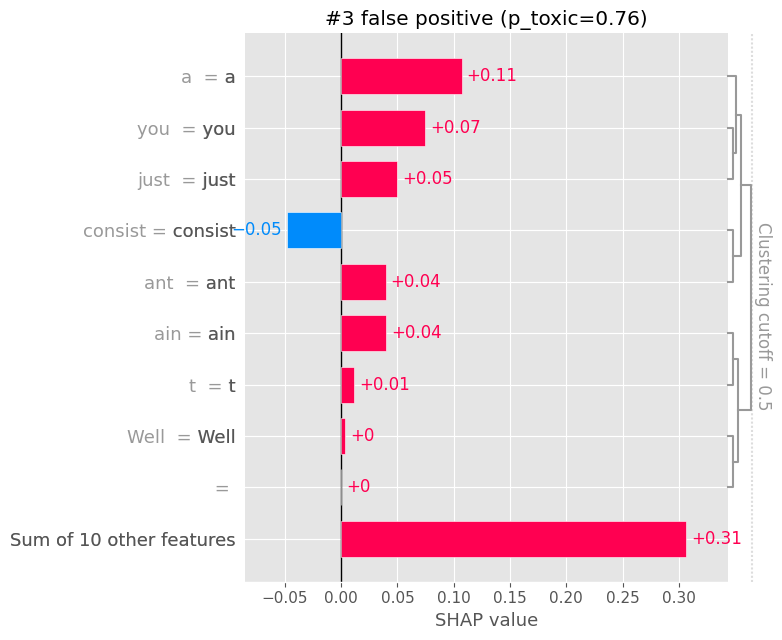

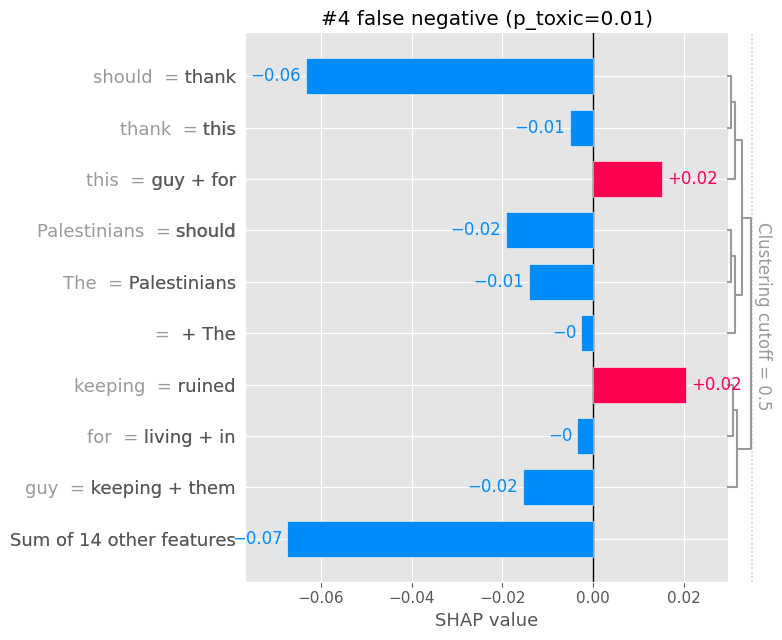

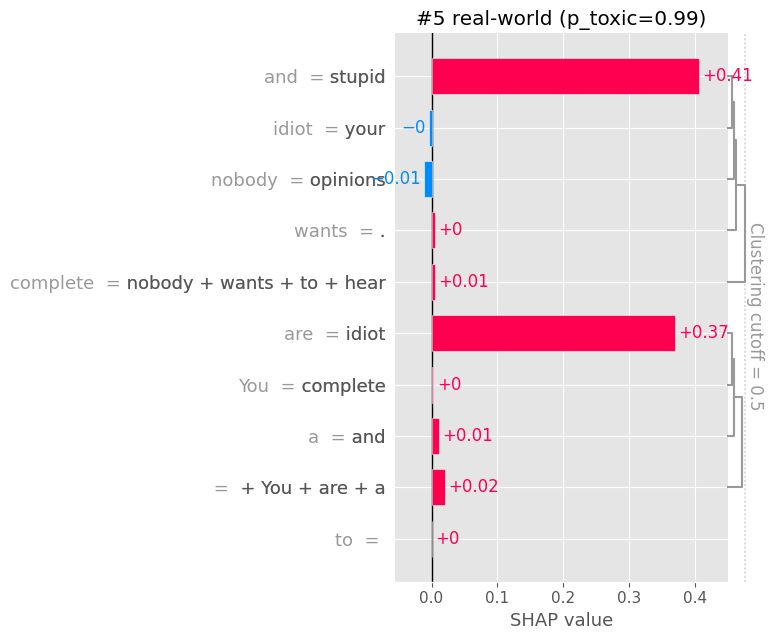

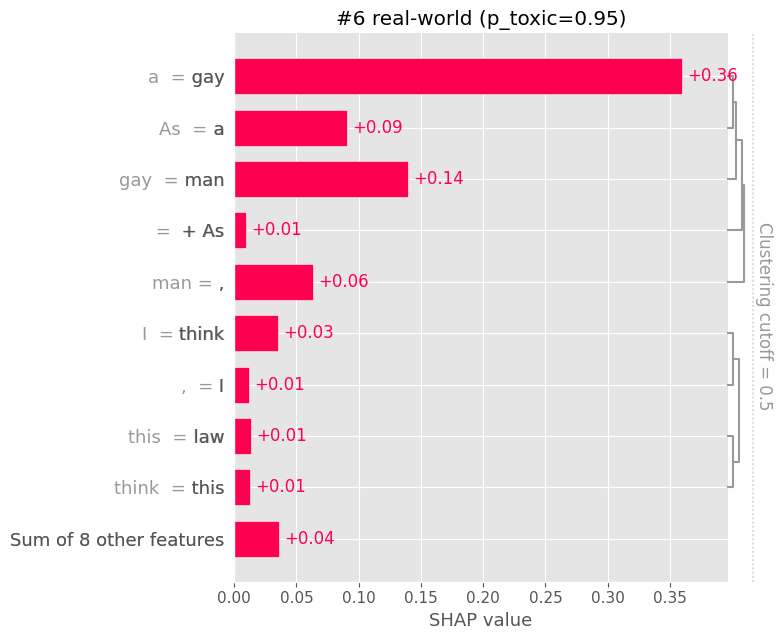

|   # | case           | true      | pred      |   p_toxic | towards toxic                                                 | towards non-toxic                                    |
|----:|:---------------|:----------|:----------|----------:|:--------------------------------------------------------------|:-----------------------------------------------------|
|   0 | true positive  | toxic     | toxic     |     0.988 | ridiculous (+0.492), . (+0.073), s (+0.065), a (+0.048)       | ? (-0.035), comment (-0.027), subscription (-0.012)  |
|   1 | true positive  | toxic     | toxic     |     0.992 | Stupid (+0.424), and (+0.123), . (+0.116), the (+0.048)       | to (-0.194), these (-0.069), property (-0.010)       |
|   2 | true negative  | non_toxic | non_toxic |     0.007 | on (+0.008)                                                   | till (-0.077), again (-0.034), Got (-0.029)          |
|   3 | false positive | non_toxic | toxic     |     0.759 | a (+0.107), . (+0.092), shrill (+0.089)

,#,case,true,pred,p_toxic,towards toxic,towards non-toxic
0,0,true positive,toxic,toxic,0.988,"ridiculous (+0.492), . (+0.073), s (+0.065), a...","? (-0.035), comment (-0.027), subscription (-0..."
1,1,true positive,toxic,toxic,0.992,"Stupid (+0.424), and (+0.123), . (+0.116), the...","to (-0.194), these (-0.069), property (-0.010)"
2,2,true negative,non_toxic,non_toxic,0.007,on (+0.008),"till (-0.077), again (-0.034), Got (-0.029)"
3,3,false positive,non_toxic,toxic,0.759,"a (+0.107), . (+0.092), shrill (+0.089), you (...","consist (-0.048), h (-0.018), (-0.000)"
4,4,false negative,toxic,non_toxic,0.011,"ruined (+0.020), guy (+0.017), like (+0.016), ...","thank (-0.063), peace (-0.036), negotiating (-..."
5,5,real-world,toxic,toxic,0.994,"stupid (+0.407), idiot (+0.370), a (+0.012), a...","opinions (-0.011), your (-0.004), wants (-0.003)"
6,6,real-world,non_toxic,toxic,0.952,"gay (+0.360), man (+0.139), a (+0.091), , (+0....","finally (-0.017), mine (-0.008)"


In [18]:
rows = []
for i in range(len(sel)):
    tokens, vals = np.array(shap_values[i].data), shap_values[i].values[:, 1]
    order = np.argsort(vals)
    top_pos = [f"{tokens[j].strip()} (+{vals[j]:.3f})" for j in order[::-1][:4] if vals[j] > 0]
    top_neg = [f"{tokens[j].strip()} ({vals[j]:.3f})" for j in order[:3] if vals[j] < 0]
    rows.append({"#": i, "case": sel.case[i], "true": ID2LABEL[int(sel.label[i])], "pred": ID2LABEL[int(sel.pred[i])],
                 "p_toxic": round(float(sel.p_toxic[i]), 3), "towards toxic": ", ".join(top_pos),
                 "towards non-toxic": ", ".join(top_neg)})
    shap.plots.bar(shap_values[i, :, 1], max_display=10, show=False)
    plt.title(f"#{i} {sel.case[i]} (p_toxic={sel.p_toxic[i]:.2f})")
    plt.tight_layout(); plt.savefig(f"{IMG_DIR}/shap_bar_{i}.png", dpi=150); plt.show()

shap_summary = pd.DataFrame(rows)
shap_summary.to_csv(f"{OUT_DIR}/shap_summary.csv", index=False)
print(shap_summary.to_markdown(index=False))
shap_summary